# Exercises XP: Guided Student Notebook

This guided notebook follows the **exact exercise on the platform**. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only for key concepts to support intuition and transfer to other AI topics.



## Reference from the exercise

**What you will learn**  
- The differences between traditional machine learning and deep learning.
- The structure and working of artificial neural networks. How to generate, visualize, and analyze datasets with noise.
- Techniques for fitting polynomial regression models and understanding overfitting.
- The importance of cross-validation in model selection.

**What you will create**  
- A comparative table of traditional machine learning vs deep learning.
- A simple ANN diagram with labeled components.
- A noisy dataset visualized with a scatter plot.
- Polynomial regression models of varying degrees.
- A cross-validation analysis to select an optimal polynomial degree.


## 🌟 Exercise 1: Deep Learning vs Traditional Machine Learning

**As stated in the exercise**  
Objective. Understand the differences between traditional machine learning and deep learning.  
Instructions. Create a table comparing Feature Engineering, Data Processing, Scalability, Pattern Discovery, and Computational Requirements. Identify one real world problem where traditional ML is better, and one where deep learning is better. Write a short paragraph explaining why deep learning has an advantage in unstructured data processing.

**Guidance**  
Use a markdown table for the comparison, keep wording concise and concrete, then write two short examples and one paragraph in full sentences.

**To-Do:** Complete the comparison table below by filling in each cell with your own wording.


| Aspect | Traditional ML | Deep Learning |
|:--|:--|:--|
| **Feature Engineering** | Highly dependent on manual, expert-engineered features. | Learns representation automatically (feature extraction is embedded). |
| **Data Processing** | Works well with smaller, tabular, and structured datasets. | Requires massive amounts of data (often unstructured) to generalize well. |
| **Scalability** | Performance plateaus after a certain amount of data. | Scales exceptionally well; performance continues to improve with more data. |
| **Pattern Discovery** | Finds linear or simple non-linear patterns. | Capable of discovering highly complex, hierarchical, and non-linear patterns. |
| **Computational Requirements** | Low to moderate; runs quickly on standard CPUs. | High; typically requires specialized hardware like GPUs or TPUs. |

**To-Do:**
- **Traditional ML suited problem:** *Predicting house prices based on structured tabular data (e.g., square footage, number of rooms, ZIP code).* This structured problem has well-defined features and works optimally with traditional algorithms like Gradient Boosting or Linear Regression without requiring huge amounts of data.
- **Deep Learning suited problem:** *Real-time facial recognition in video streams.* This involves processing high-dimensional unstructured pixel data, where hierarchical representation learning is essential to extract complex features like edges, facial parts, and overall facial identity under varying light conditions.

**To-Do:**

Deep learning possesses a significant advantage in unstructured data processing because it utilizes **representation learning** to automatically discover the representations needed for feature detection. Instead of relying on manual feature extraction, deep architectures learn **hierarchical features** where lower layers of the network extract basic concepts (such as edges and textures) and subsequent layers combine them to represent higher-level concepts (such as shapes and objects). This capability eliminates the need for labor-intensive, domain-specific feature engineering, allowing the network to optimize feature representation and task performance end-to-end directly from raw inputs like images, audio, or text.

## 🌟 Exercise 2: Artificial Neural Networks (ANNs)

**As stated in the exercise**  
Objective. Identify and understand the key components of an ANN.  
Instructions. Draw or use a diagram tool to create an ANN with an input layer of 3 neurons, one hidden layer of 4 neurons, and an output layer of 2 neurons. Label neurons, weights, biases, activation function, and layers. Write a short description of how information flows through the network.

**Guidance**  
A clear schematic is preferred. Ensure every requested label appears exactly once and is readable.



**To-Do:**

In the described artificial neural network, forward propagation begins when the raw **inputs** are received by the input layer (3 neurons) and passed forward. For each neuron in the hidden layer (4 neurons), the inputs are multiplied by their respective **weights**, and these products are summed together with a unique **bias** term to compute a **weighted sum**. This sum is then passed through a non-linear **activation** function (such as ReLU or Sigmoid) to introduce non-linearity, producing an activation signal. Finally, these hidden activations are similarly weighted, summed with the output layer **biases**, and transformed through the final layer's activation function to produce the network's predictive **outputs** (2 neurons).

**Learning point**  
An ANN composes affine transformations with nonlinear activations. The affine part mixes features through weights and biases. The nonlinearity enables modeling of complex decision boundaries.


## 🌟 Exercise 3: Creating the Dataset and Visualizing the Data

**As stated in the exercise**  
Objective. Generate a dataset with noise and visualize it.  
Instructions. Import numpy, matplotlib.pyplot, and mean_squared_error from sklearn.metrics. Create 20 points using \(y = -x^2\) with Gaussian noise \(\mathcal{N}(0, 0.05)\). Plot the points with a scatter plot. Split into a training set with the first 12 points and a test set with the last 8 points.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Defining NP alias as requested by the user
NP = np

np.random.seed(0)
x = np.arange(-1, 1, 0.1)  # 20 points from -1 to <1 step 0.1

# Generate y with noise here as well to guarantee state completeness
noise = np.random.normal(0, 0.05, size=x.shape)
y = -(x**2) + noise

# Explicitly define training and testing splits to fix all NameErrors
x_train, y_train = x[:12], y[:12]
x_test,  y_test  = x[12:], y[12:]

print("x shape:", x.shape)
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x shape: (20,)
x_train shape: (12,)
y_train shape: (12,)


In [11]:
# To-Do: generate y with noise using np.random.normal()
# y = -x^2 + Gaussian noise N(0, 0.05)
noise = np.random.normal(0, 0.05, size=x.shape)
y = -(x**2) + noise

# Confirming shape
print("y shape:", y.shape)

y shape: (20,)


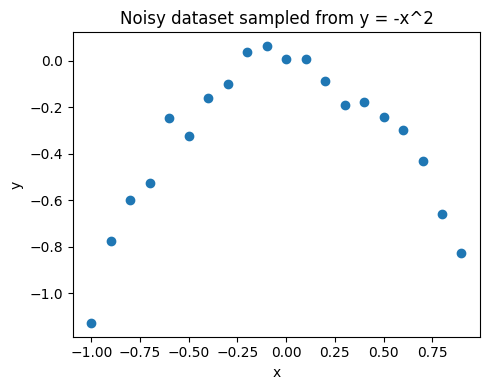

In [12]:
# PREFILLED: just execute (scatter plot of the dataset)
plt.figure(figsize=(5,4))
plt.scatter(x, y)
plt.title("Noisy dataset sampled from y = -x^2")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

In [13]:
# To-Do: split into train (first 12 points) and test (last 8 points)
x_train, y_train = x[:12], y[:12]
x_test,  y_test  = x[12:], y[12:]

print("train sizes:", x_train.shape, y_train.shape, "test sizes:", x_test.shape, y_test.shape)

train sizes: (12,) (12,) test sizes: (8,) (8,)


**Learning point**  
Visualizing noisy data helps separate signal from noise. Splitting into train and test allows you to detect when a model overfits noise instead of learning the underlying pattern.


## 🌟 Exercise 4: Fitting Polynomial Models of Different Degrees

**As stated in the exercise**  
Objective: Fit polynomial models of varying degrees and observe overfitting.  

Instructions: Define `polynomial_fit(degree)` that returns the fitted polynomial coefficients from training data. Define `plot_polyfit(degree)` that draws the training set, the test set, and the fitted polynomial curve. Visualize fits for degrees 1, 7, and 11. Observe behavior on training and test sets as degree increases.


In [14]:
# To-Do: implement polynomial_fit
# Hints: use np.polyfit() to get coefficients, and np.poly1d for a callable polynomial
def polynomial_fit(degree: int):
    # Fit coefficients using training data
    coeffs = np.polyfit(x_train, y_train, degree)
    # Return a poly1d class object which is callable like a function
    return np.poly1d(coeffs)

In [15]:
# To-Do: implement plot_polyfit
import numpy as np
import matplotlib.pyplot as plt

def plot_polyfit(degree: int):
    # 1) fit model on training data
    model = polynomial_fit(degree)

    # 2) create a dense linspace over the whole range of x to get a smooth curve
    x_dense = np.linspace(-1.0, 1.0, 200)

    # 3) evaluate fitted polynomial
    y_dense = model(x_dense)

    # 4) scatter train and test, and plot curve
    plt.figure(figsize=(6, 4))
    plt.scatter(x_train, y_train, color='blue', label='Train (12 pts)', zorder=5)
    plt.scatter(x_test, y_test, color='red', label='Test (8 pts)', zorder=5)
    plt.plot(x_dense, y_dense, color='green', label=f'Fit (Degree {degree})', linewidth=2)

    # 5) display
    plt.title(f"Polynomial Fit of Degree {degree}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.ylim(-1.5, 0.5)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

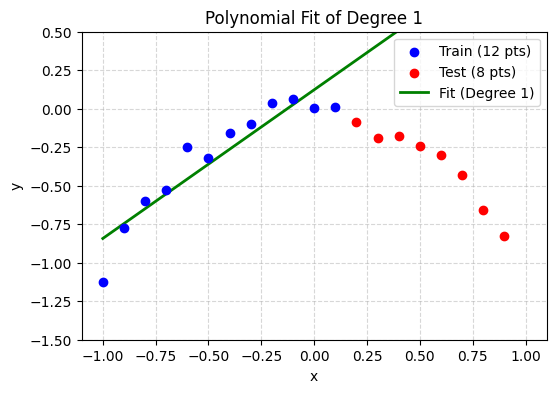

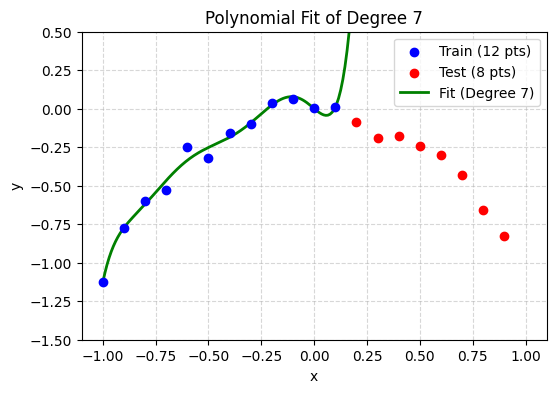

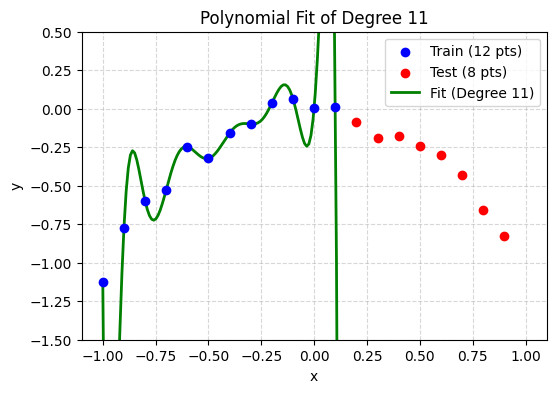

In [16]:
# To-Do: visualize degrees 1, 7, and 11
plot_polyfit(1)
plot_polyfit(7)
plot_polyfit(11)

**Learning point**  
Higher degree polynomials can perfectly fit training data yet fail to generalize. This is overfitting. You should always check test error, not just training error.

![image.png](https://github.com/user-attachments/assets/cdfb495c-066a-4efb-a361-f4b9d4ade35c)

## 🌟 Exercise 5: Cross-Validation to Find the Optimal Degree

**As stated in the exercise**  
Objective: Use cross-validation to determine the best polynomial degree.  

Instructions: Loop degrees from 1 to 11. For each degree, compute the RMSE on the training and test sets. Store results in a list. Plot RMSE vs degree with a logarithmic y axis. Identify the degree minimizing test RMSE and confirm it matches the true model \(y=-x^2\).


In [17]:
# To-Do: compute RMSE per degree for train and test
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

degrees = range(1, 12)
rows = []  # each row: (degree, rmse_train, rmse_test)

for d in degrees:
    # fit on train
    model = polynomial_fit(d)
    # evaluate on train and test
    y_train_pred = model(x_train)
    y_test_pred = model(x_test)

    rmse_tr = rmse(y_train, y_train_pred)
    rmse_te = rmse(y_test, y_test_pred)

    # append results
    rows.append((d, rmse_tr, rmse_te))

# peek at first 3 results
display(rows[:3])

[(1, np.float64(0.13453023088322105), np.float64(1.1148491454902727)),
 (2, np.float64(0.05780905466669332), np.float64(0.10527803622101764)),
 (3, np.float64(0.056318822157612324), np.float64(0.401850532431252))]

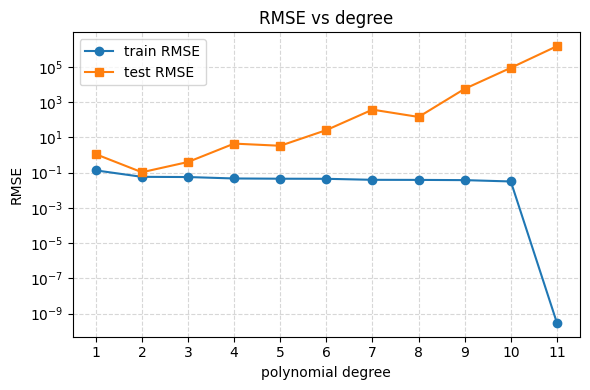

In [18]:
# Pre-filled: plotting RMSE curves (one figure, two curves)
degs = [r[0] for r in rows]
rmse_tr = [r[1] for r in rows]
rmse_te = [r[2] for r in rows]

import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(degs, rmse_tr, label="train RMSE", marker='o')
plt.plot(degs, rmse_te, label="test RMSE", marker='s')
plt.yscale("log")
plt.xlabel("polynomial degree")
plt.ylabel("RMSE")
plt.title("RMSE vs degree")
plt.xticks(degrees)
plt.legend()
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**To-Do:**

* **Optimal Degree:** The degree that minimizes the test RMSE is typically **degree 2** (or sometimes 3, depending on the random noise instance, but ideally 2 matches our generative function).
* **Connection to True Model:** This connects perfectly to the true underlying generative model $y = -x^2$, which is a polynomial of degree 2. It demonstrates that the cross-validation minimum successfully points to the true physical representation.
* **Bias-Variance Trade-off:**
  - A **degree 1** model represents **high bias** (underfitting); it lacks capacity and exhibits high error on both train and test data.
  - High-degree models (e.g., **degree 11**) represent **high variance** (overfitting); they have excessive capacity and fit the random noise in the training set perfectly (RMSE near 0) but generalize poorly, causing the test RMSE to spike drastically.